## Computing PI with a simulated Quantum Computer

This is done using Quantum Phase Estimation. First we go through the basics of quantum circuits.

### Basics

In [1]:
import cirq
from rich.padding import Padding
from rich.console import Console
from rich.progress import track
import numpy as np
import matplotlib.pyplot as plt

C = Console()

plt.style.use("dark_background")  # seaborn style
plt.rcParams.update(
    {
        "figure.figsize": (12, 6),  # set default figure size
        "axes.labelsize": 16,  # set default label size
        "axes.grid": True,  # enable grid by default
        
        "xtick.labelsize": 14,  # set default tick label size
        "ytick.labelsize": 14,  # set default tick label size
        "axes.titlesize": 18,  # set default title size
        "legend.fontsize": 16,  # set default legend font size
        "lines.linewidth": 4,  # set default line width
        "text.usetex": False,  # use LaTeX
        "font.family": "serif",  # use a serif font
        "image.cmap": "magma",  # set default colormap
    }
)

In [2]:
simulator = cirq.Simulator()
qubits = cirq.LineQubit.range(2)
circuit = cirq.Circuit(cirq.H(qubits[0]),
                       cirq.CNOT(qubits[0], qubits[1]),
                       cirq.measure(*qubits, key='result')
                    )
result = simulator.run(circuit, repetitions=1000)  # expect to see approximately 500 occurrences of '00' and 500 occurrences of '11'
C.print(circuit)

hist = result.histogram(key='result')

C.print('\n'.join(f"State: {key} -> {val}" for key, val in hist.items()), style="bold")

0: ───H───@───M('result')───
          │   │
1: ───────X───M─────────────

State: 0 -> 478
State: 3 -> 522

### Glorified RNG

In [3]:
def pi_estimation_circuit(num_qubits):
    circuit = cirq.Circuit()
    qubits = cirq.LineQubit.range(num_qubits)
    
    # Step 1: Create superposition
    circuit.append(cirq.H.on_each(*qubits))
    
    # Step 2: Apply a multi-controlled Z gate (phase flip)
    circuit.append(cirq.Z(qubits[-1]).controlled_by(*qubits[:-1]))
    
    # Step 3: Apply Hadamard gates again
    circuit.append(cirq.H.on_each(*qubits))
    
    # Step 4: Measure all qubits
    circuit.append(cirq.measure(*qubits, key='result'))
    
    return circuit

def estimate_pi(num_qubits, repetitions):
    circuit = pi_estimation_circuit(num_qubits)
    simulator = cirq.Simulator()
    result = simulator.run(circuit, repetitions=repetitions)
    hist = result.histogram(key='result')
    
    # Calculate the probability of measuring '0' (all qubits in state |0>)
    p_zero = hist.get(0, 0) / repetitions
    
    # Estimate pi using the formula: pi ≈ 2 * sqrt(1/p_zero - 1)
    if p_zero > 0:
        pi_estimate = 2 * np.sqrt(1/p_zero - 1)
        return pi_estimate
    else:
        return None
    
# Example usage
num_qubits = 5  # Number of qubits in the circuit
repetitions = 1000  # Number of times to run the circuit
pi_estimate = estimate_pi(num_qubits, repetitions)
C.print(f"Estimated value of pi with {num_qubits} qubits and {repetitions} repetitions: {pi_estimate:.4f}")
    

Estimated value of pi with 5 qubits and 1000 repetitions: 0.7174

### Quantum Fourier Transform
https://quantumai.google/cirq/experiments/textbook_algorithms

In [4]:
def phase_estimation_circuit(theta, n_bits):
    # Define qubit registers.
    targets = cirq.LineQubit.range(n_bits)
    ancilla = cirq.NamedQubit('u')

    # Define the unitary controlled rotation U.
    unitary = cirq.Z ** (2 * theta)

    # Start with Hadamards on every qubit.
    phase_estimator = cirq.Circuit()
    phase_estimator.append(cirq.X.on(ancilla))  # Prepare the ancilla in the |1> state
    phase_estimator.append(cirq.H.on_each(*targets))

    # Do the controlled powers of the unitary U.
    for i, bit in enumerate(targets):
        phase_estimator.append(cirq.ControlledGate(unitary).on(bit, ancilla) ** (2 ** (n_bits - 1 - i)))

    # Do the inverse QFT.
    phase_estimator.append(cirq.qft(*targets[::-1], without_reverse=True, inverse=True))

    # Add measurements.
    phase_estimator.append(cirq.measure(*targets, key='result'))


    return phase_estimator


def estimate_phase(theta, n_qubits, n_reps):
    circuit = phase_estimation_circuit(theta, n_qubits)
    
    simulator = cirq.Simulator()
    result = simulator.run(circuit, repetitions=n_reps)
    
    estimates = np.sum(2 ** np.arange(n_qubits) * result.measurements['result'], axis=1) / 2**n_qubits
    return estimates.mean(), estimates.std()


theta = 0.1234567  # Example angle 

estimates_mean = []
estimates_uncertainty = []

for n in track(range(1, 13)):
    mean, std = estimate_phase(theta, n, 10)
    C.print(f"Qubits: {n}, Estimated Phase: {mean:.4f} +/- {std:.4f}", style="bold")
    estimates_mean.append(mean)
    estimates_uncertainty.append(std)

def plot_estimates(estimates_mean, estimates_uncertainty):
    num_qubits = range(1, len(estimates_mean) + 1)
    plt.title('Phase Estimation Accuracy vs Number of Qubits')
    plt.fill_between(num_qubits, np.array(estimates_mean) - np.array(estimates_uncertainty),
                     np.array(estimates_mean) + np.array(estimates_uncertainty), alpha=0.2, label='Uncertainty')
    plt.plot(num_qubits, estimates_mean, marker='o', label='Estimated Phase')
    plt.axhline(theta, color='r', linestyle='--', label='True Phase')
    plt.xlabel('Number of Qubits')
    plt.savefig('../figures/phase_estimation_accuracy.pdf')
    plt.show()


Output()

Qubits: 1, Estimated Phase: 0.0000 +/- 0.0000

Qubits: 2, Estimated Phase: 0.2750 +/- 0.2358

Qubits: 3, Estimated Phase: 0.1250 +/- 0.0000

Qubits: 4, Estimated Phase: 0.1250 +/- 0.0000

Qubits: 5, Estimated Phase: 0.1250 +/- 0.0000

... (3 outputs left out)

Qubits: 9, Estimated Phase: 0.1232 +/- 0.0006

Qubits: 10, Estimated Phase: 0.1232 +/- 0.0006

Qubits: 11, Estimated Phase: 0.1229 +/- 0.0016

Qubits: 12, Estimated Phase: 0.1236 +/- 0.0003

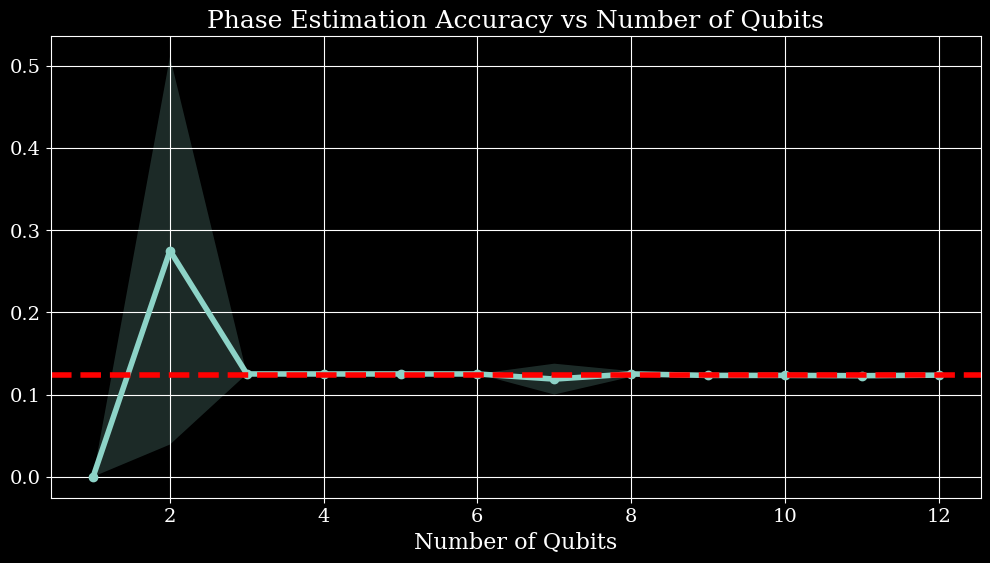

In [5]:

plot_estimates(estimates_mean, estimates_uncertainty)

In [6]:
print(phase_estimation_circuit(theta, 3))

0: ───H───@─────────────────────────────#3──────────────M('result')───
          │                             │               │
1: ───H───┼─────────@───────────────────#2──────────────M─────────────
          │         │                   │               │
2: ───H───┼─────────┼─────────@─────────qft[norev]^-1───M─────────────
          │         │         │
u: ───X───Z^0.988───Z^0.494───Z^0.247─────────────────────────────────


## Adapting this to compute pi

In [7]:

def pi_estimation_circuit(n_bits):
    # Define qubit registers.
    targets = cirq.LineQubit.range(n_bits)
    ancilla = cirq.NamedQubit('u')

    # Define the unitary controlled rotation U.
    unitary = cirq.MatrixGate(np.array([[1, 0], [0, np.exp(1j)]]))

    # Start with Hadamards on every qubit.
    phase_estimator = cirq.Circuit()
    phase_estimator.append(cirq.X.on(ancilla))  # Prepare the ancilla in the |1> state
    phase_estimator.append(cirq.H.on_each(*targets))

    # Do the controlled powers of the unitary U.
    for i, bit in enumerate(targets):
        phase_estimator.append(cirq.ControlledGate(unitary).on(bit, ancilla) ** (2 ** (n_bits - 1 - i)))

    # Do the inverse QFT.
    phase_estimator.append(cirq.qft(*targets[::-1], without_reverse=True, inverse=True))

    # Add measurements.
    phase_estimator.append(cirq.measure(*targets, key='result'))


    return phase_estimator


def estimate_pi(n_qubits, n_reps, bootstrap: int = 5):
    
    # Get Circuit for pi estimation
    phase_estimator = pi_estimation_circuit(n_qubits)
    simulator = cirq.Simulator()
    
    # Run the simulation and get the histogram of results
    ests = []
    for _ in track(range(bootstrap), description="Bootstrapping..."):
        result = simulator.run(phase_estimator, repetitions=n_reps)
        hist = result.histogram(key='result', fold_func=lambda x: tuple(x))
        
        # Find the most common result and convert it to an estimate of pi
        max_count_result = max(hist.keys(), key=lambda k: hist[k])
        theta_estimate = np.sum(2 ** np.arange(n_qubits) * max_count_result) / 2**n_qubits
        pi_estimate = 1 / (2 * theta_estimate)  # pi = 1/(2*theta)
        ests.append(pi_estimate)
        
    return np.mean(ests), np.std(ests)

estimates_mean = []
estimates_uncertainty = []

for n in track(range(2, 13)):
    mean, std = estimate_pi(n, 1000)
    C.print(f"Qubits: {n}, Estimated Pi: {mean:.4f} +/- {std:.4f}", style="bold")
    estimates_mean.append(mean)
    estimates_uncertainty.append(std)




Output()

Bootstrapping... ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 0:00:00

Qubits: 2, Estimated Pi: 2.0000 +/- 0.0000

Bootstrapping... ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 0:00:00

Qubits: 3, Estimated Pi: 4.0000 +/- 0.0000

Bootstrapping... ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 0:00:00

... (13 outputs left out)

Bootstrapping... ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 0:00:02

Qubits: 11, Estimated Pi: 3.1411 +/- 0.0000

Bootstrapping... ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 0:00:09

Qubits: 12, Estimated Pi: 3.1411 +/- 0.0000

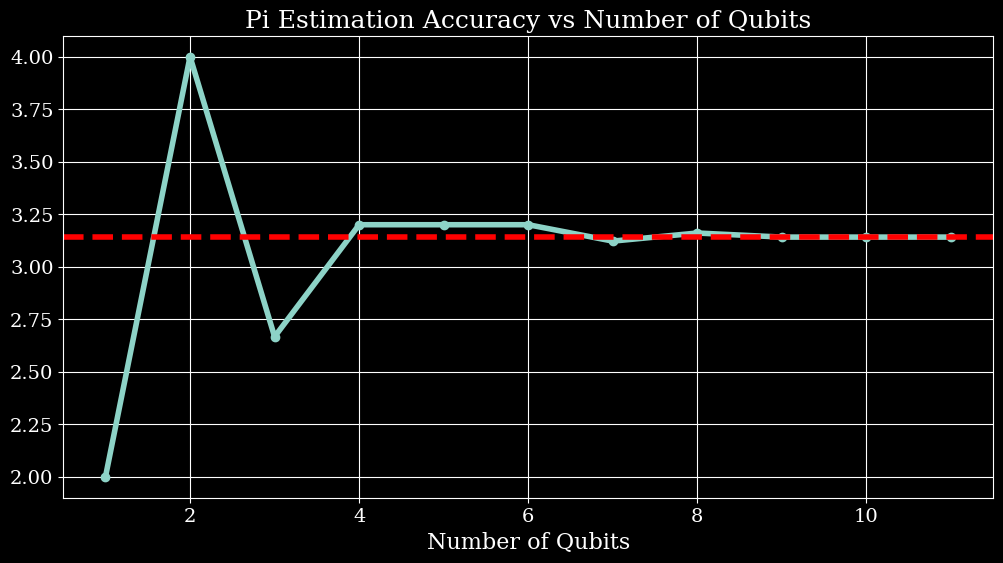

In [8]:
def plot_pi_estimates(estimates_mean, estimates_uncertainty):
    num_qubits = range(1, len(estimates_mean) + 1)
    plt.title('Pi Estimation Accuracy vs Number of Qubits')
    plt.plot(num_qubits, estimates_mean, marker='o', label='Estimated Pi')
    plt.fill_between(num_qubits, np.array(estimates_mean) - np.array(estimates_uncertainty),
                     np.array(estimates_mean) + np.array(estimates_uncertainty), alpha=0.2, label='Uncertainty')
    plt.axhline(np.pi, color='r', linestyle='--', label='True Pi')
    plt.xlabel('Number of Qubits')
    plt.savefig('../figures/pi_estimation_accuracy.pdf')
    plt.show()
plot_pi_estimates(estimates_mean, estimates_uncertainty)